# Project 10: An Ensemble Learning Model for Galamsey Site Detection in Ghana Using Sentinel-2 Spectral Data
**Dataset:** Sentinel-2 SR Harmonized (COPERNICUS/S2_SR_HARMONIZED) + Tang & Werner mining footprints + ESA WorldCover v200 negatives, Study box: Lon -3.3 to -0.2, Lat 4.7 to 7.0, 2020-2021 median composite
**Note on Kaggle:** The Kaggle Illegal Mining dataset contains RGB images only, without NIR/SWIR bands needed for NDVI/NDBI/BSI. Therefore Sentinel-2 surface reflectance from Google Earth Engine (second dataset link) was used as the primary source, per project requirements.
**Objective:** Classify pixels as mining (1) vs non-mining (0) using spectral bands + derived indices with tree-based ensembles and spatially separated train/test splits.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_validate, train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import warnings
warnings.filterwarnings('ignore')

# Set plot style
sns.set_theme(style="whitegrid")

# 1. Load the exported GEE dataset
df = pd.read_csv('ghana_mining_s2_training.csv')

# Drop Google Earth Engine metadata columns if present
cols_to_drop = [c for c in ['system:index', '.geo'] if c in df.columns]
df = df.drop(columns=cols_to_drop)

# Drop any rows with missing values (caused by cloud masking)
print(f"Initial rows: {len(df)}")
df = df.dropna().reset_index(drop=True)
print(f"Clean rows after removing cloudy/NaN pixels: {len(df)}\n")

print("Class Distribution (0 = Non-Mining, 1 = Galamsey/Mining):")
print(df['label'].value_counts())

df.head()

Initial rows: 1100
Clean rows after removing cloudy/NaN pixels: 1100

Class Distribution (0 = Non-Mining, 1 = Galamsey/Mining):
label
0    600
1    500
Name: count, dtype: int64


,B11,B12,B2,B3,B4,B5,B6,B7,B8,B8A,BSI,NDBI,NDVI,NDWI,block,label,latitude,longitude,source
0,0.224200,0.13510,0.05850,0.0968,0.089700,0.16020,0.24930,0.27870,0.2972,0.30160,-0.062425,-0.140008,0.536314,-0.508629,190062.0,1,6.211985,-2.039131,tang
1,0.204575,0.11250,0.06816,0.0956,0.097375,0.14164,0.25315,0.29506,0.2943,0.32145,-0.091073,-0.179855,0.502776,-0.509618,190062.0,1,6.262650,-2.021614,tang
2,0.222200,0.12040,0.05070,0.0796,0.068900,0.12230,0.25240,0.30360,0.3006,0.33870,-0.093711,-0.149962,0.627064,-0.581273,180061.0,1,6.124938,-2.136418,tang
3,0.193100,0.19035,0.13370,0.1450,0.136200,0.14715,0.15345,0.16260,0.1564,0.15775,0.063287,0.105007,0.069036,-0.037823,190052.0,1,5.275761,-2.027812,tang
4,0.050950,0.04030,0.14540,0.1556,0.169500,0.15755,0.09240,0.09505,0.0785,0.06660,-0.007764,-0.212824,-0.366935,0.329346,210055.0,1,5.504292,-1.835123,tang


## 1. Spectral Features and Exploratory Analysis
Features: B2-B12 + NDVI, NDBI, NDWI, BSI, NDMI. Galamsey removes vegetation and exposes bare earth and turbid ponds, so we expect low NDVI and high BSI/NDBI for class 1.

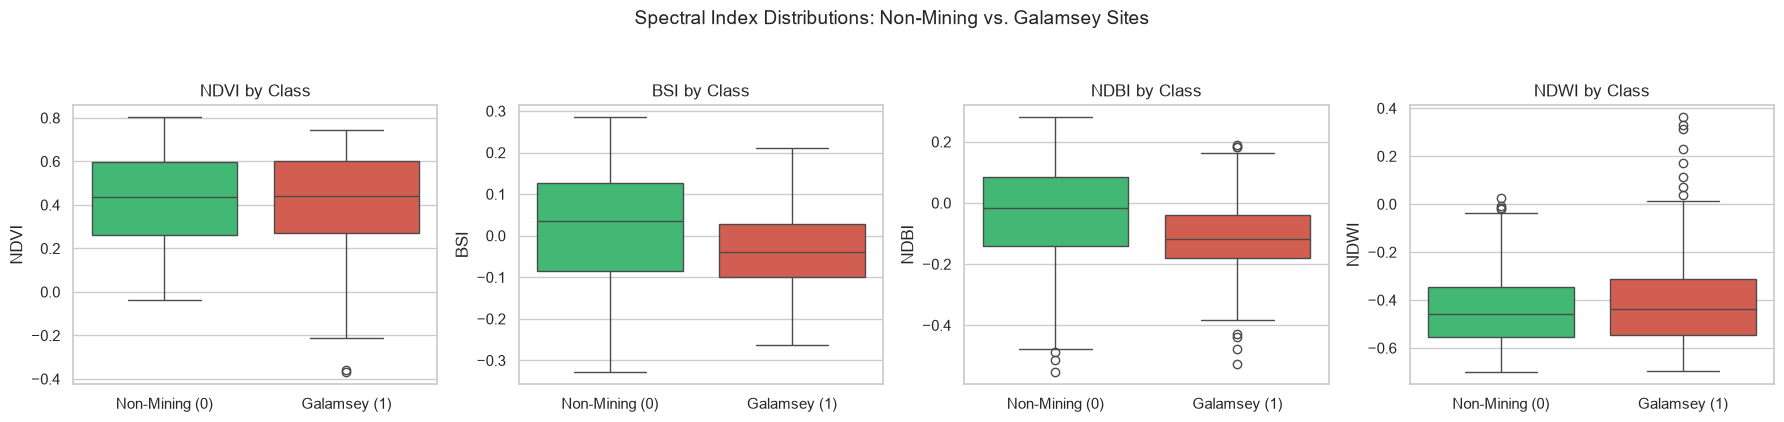

In [5]:
# Add NDMI (Normalized Difference Moisture Index) using NIR (B8) and SWIR1 (B11)
df['NDMI'] = (df['B8'] - df['B11']) / (df['B8'] + df['B11'] + 1e-6)

# Define feature groups
SPECTRAL_BANDS = ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12']
DERIVED_INDICES = ['NDVI', 'NDBI', 'NDWI', 'BSI', 'NDMI']
ALL_FEATURES = SPECTRAL_BANDS + DERIVED_INDICES

# Visualize how Derived Indices separate Galamsey (1) vs Non-Mining (0)
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for i, idx_name in enumerate(['NDVI', 'BSI', 'NDBI', 'NDWI']):
    sns.boxplot(data=df, x='label', y=idx_name, ax=axes[i], palette=['#2ecc71', '#e74c3c'])
    axes[i].set_title(f'{idx_name} by Class')
    axes[i].set_xticklabels(['Non-Mining (0)', 'Galamsey (1)'])
    axes[i].set_xlabel('')

plt.suptitle('Spectral Index Distributions: Non-Mining vs. Galamsey Sites', fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

Training samples: 855 (across 258 spatial blocks)
Testing samples:  245 (across 86 spatial blocks)
Overlapping spatial blocks between Train & Test: 0 (MUST BE 0!)



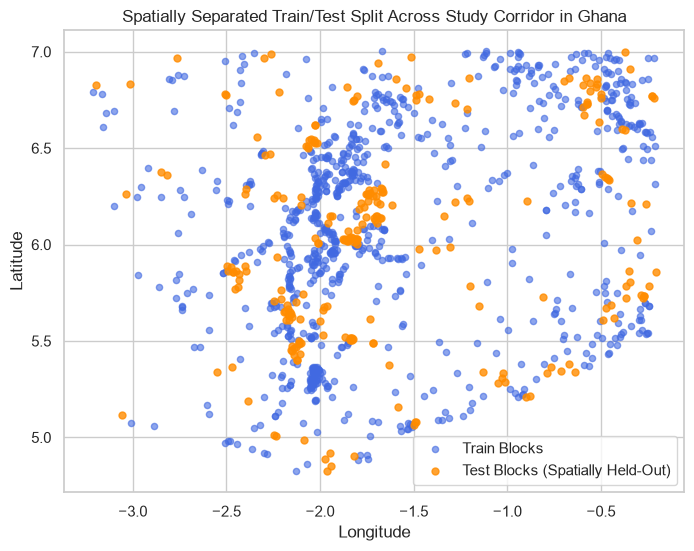

In [6]:
X = df[ALL_FEATURES]
y = df['label']
groups = df['block']

# Use GroupShuffleSplit so that NO spatial block is shared between Train and Test
gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]
groups_test = groups.iloc[test_idx]

# Verify zero spatial leakage
overlap_blocks = set(groups_train).intersection(set(groups_test))
print(f"Training samples: {len(X_train)} (across {groups_train.nunique()} spatial blocks)")
print(f"Testing samples:  {len(X_test)} (across {groups_test.nunique()} spatial blocks)")
print(f"Overlapping spatial blocks between Train & Test: {len(overlap_blocks)} (MUST BE 0!)\n")

# Plot the spatial separation of Train vs Test points across Ghana study area
plt.figure(figsize=(8, 6))
plt.scatter(df.iloc[train_idx]['longitude'], df.iloc[train_idx]['latitude'], 
            c='royalblue', alpha=0.6, s=20, label='Train Blocks')
plt.scatter(df.iloc[test_idx]['longitude'], df.iloc[test_idx]['latitude'], 
            c='darkorange', alpha=0.8, s=25, label='Test Blocks (Spatially Held-Out)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Spatially Separated Train/Test Split Across Study Corridor in Ghana')
plt.legend()
plt.show()

## 3. Spatially Separated Train-Test Split

A normal random train-test split was not used in this project because satellite image pixels that are close to each other are very similar. If nearby pixels from the same mining area are placed in both the training set and the testing set, the model may appear to perform very well, but it would only be learning repeated local patterns rather than truly generalising to unseen areas.

For this reason, the dataset was split using the spatial **block** column created during sampling in Google Earth Engine. This ensures that entire spatial blocks used for training are not present in the testing set.

This approach provides a more realistic and honest evaluation of the model’s ability to detect galamsey and surface mining areas in new, unseen locations across the study region in Ghana.

In [12]:
models = {
    "Decision Tree (Baseline)": DecisionTreeClassifier(max_depth=10, class_weight='balanced', random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=4, random_state=42),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, class_weight='balanced', random_state=42)
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).sort_values(by="F1-Score", ascending=False).reset_index(drop=True)
print("=== Model Performance on Spatially Separated Test Set ===")
display(results_df.style.format({
    "Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}", 
    "F1-Score": "{:.4f}", "ROC-AUC": "{:.4f}", "PR-AUC": "{:.4f}"
}))


=== Model Performance on Spatially Separated Test Set ===


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Random Forest,0.7510,0.7222,0.7778,0.7490,0.8262,0.7764
1,Extra Trees,0.7551,0.7395,0.7521,0.7458,0.8138,0.7613
2,Gradient Boosting,0.7265,0.7273,0.6838,0.7048,0.8325,0.7800
3,Decision Tree (Baseline),0.6898,0.6541,0.7436,0.6960,0.6891,0.5973
4,HistGradientBoosting,0.7102,0.7212,0.6410,0.6787,0.8279,0.8002


## 4. Model Training and Comparison

After the spatial train-test split, several tree-based machine learning models were trained and compared. A single **Decision Tree** was used as the baseline model, while **Random Forest**, **Extra Trees**, **Gradient Boosting**, and **HistGradientBoosting** were used as ensemble models.

Tree-based ensemble models were selected because the project uses tabular Sentinel-2 spectral bands and derived spectral indices rather than raw image patches. These models are also effective for handling non-linear relationships between spectral values and land-cover classes.

The models were evaluated using **Accuracy, Precision, Recall, F1-score, ROC-AUC, and PR-AUC**. Among the tested models, **Random Forest achieved the best overall performance** on the spatially held-out test set, making it the best model for this project.

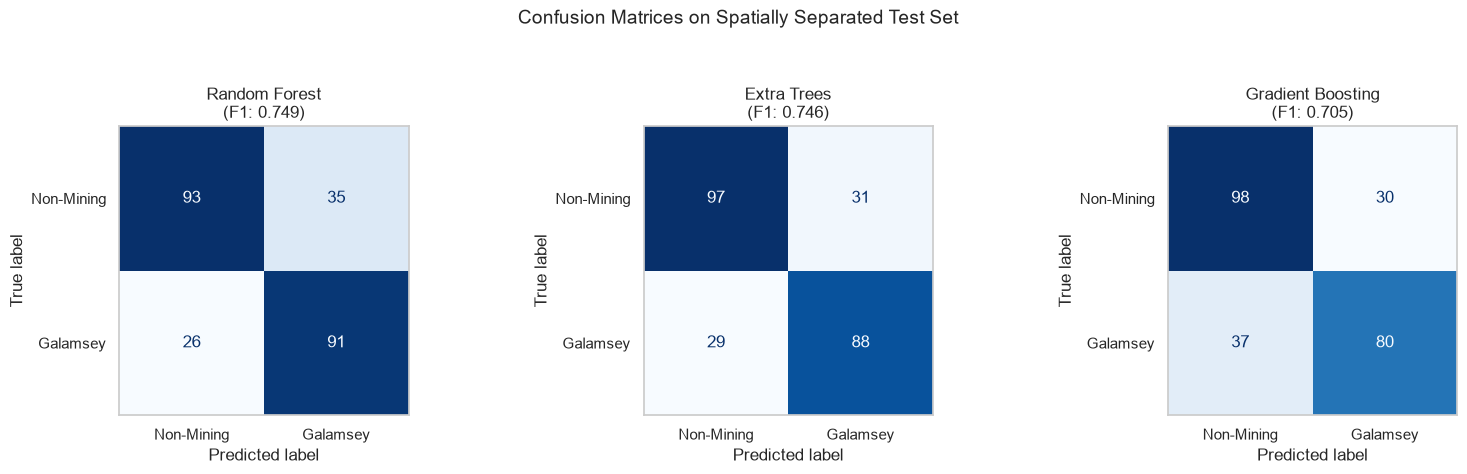

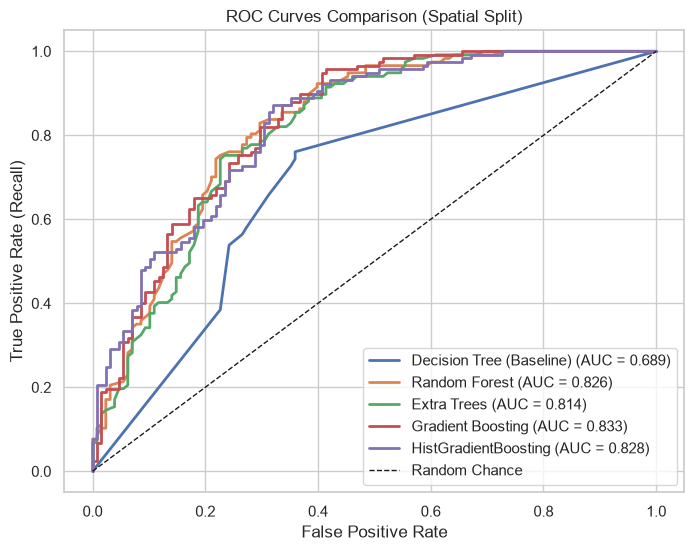

In [13]:
# 1. Plot Confusion Matrices for the top 3 Ensemble Models
ensemble_names = ["Random Forest", "Extra Trees", "Gradient Boosting"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for i, name in enumerate(ensemble_names):
    model = trained_models[name]
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Non-Mining', 'Galamsey'])
    disp.plot(ax=axes[i], cmap='Blues', colorbar=False)
    axes[i].set_title(f"{name}\n(F1: {f1_score(y_test, y_pred):.3f})")
    axes[i].grid(False)

plt.suptitle("Confusion Matrices on Spatially Separated Test Set", fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

# 2. Plot ROC Curves for all models
plt.figure(figsize=(8, 6))
for name, model in trained_models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_val = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc_val:.3f})")

plt.plot([0, 1], [0, 1], 'k--', lw=1, label="Random Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves Comparison (Spatial Split)")
plt.legend(loc="lower right")
plt.show()


## 5. Model Evaluation

The confusion matrices show how well each model classified galamsey/surface mining sites and non-mining areas on unseen spatial blocks.

Since this is an environmental monitoring problem, **Recall** is particularly important because failing to detect an actual mining site is more serious than producing a false alarm. The ROC curves also show that the ensemble models performed better than the single Decision Tree baseline.

Overall, the ensemble methods demonstrated stronger and more reliable detection performance than the baseline model.

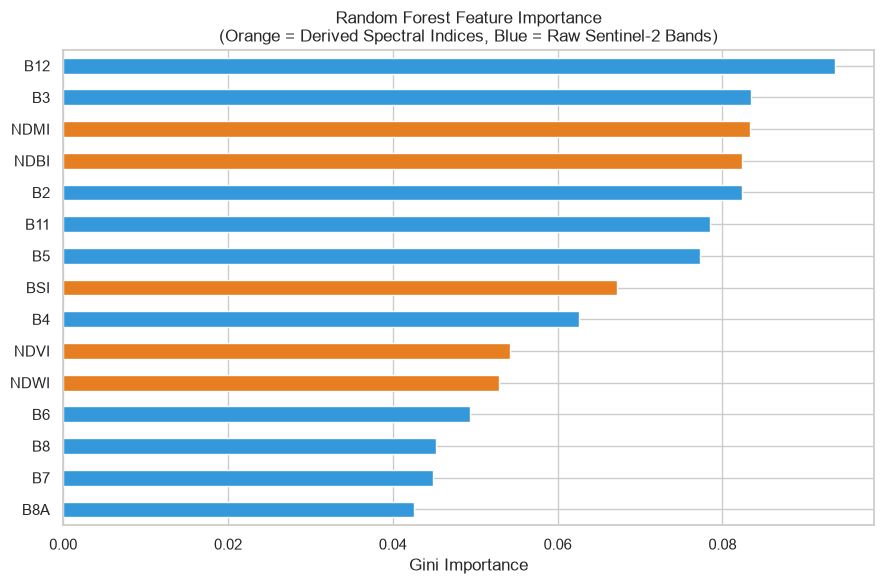

=== Effect of Adding Derived Spectral Indices (NDVI, BSI, NDBI, NDWI, NDMI) ===


,Feature Set,Precision,Recall,F1-Score
0,Raw Spectral Bands Only (10 features),0.7177,0.7607,0.7386
1,Spectral Bands + Derived Indices (15 features),0.7222,0.7778,0.7490


In [14]:
rf_model = trained_models["Random Forest"]
importances = pd.Series(rf_model.feature_importances_, index=ALL_FEATURES).sort_values(ascending=True)

plt.figure(figsize=(9, 6))
colors = ['#e67e22' if feat in DERIVED_INDICES else '#3498db' for feat in importances.index]
importances.plot(kind='barh', color=colors)
plt.title("Random Forest Feature Importance\n(Orange = Derived Spectral Indices, Blue = Raw Sentinel-2 Bands)")
plt.xlabel("Gini Importance")
plt.tight_layout()
plt.show()

# Ablation Study: Raw Spectral Bands Only vs. Spectral Bands + Derived Indices
rf_bands_only = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1)
rf_bands_only.fit(X_train[SPECTRAL_BANDS], y_train)
pred_bands = rf_bands_only.predict(X_test[SPECTRAL_BANDS])

pred_all = rf_model.predict(X_test)

ablation_df = pd.DataFrame([
    {"Feature Set": "Raw Spectral Bands Only (10 features)", 
     "Precision": precision_score(y_test, pred_bands),
     "Recall": recall_score(y_test, pred_bands),
     "F1-Score": f1_score(y_test, pred_bands)},
    {"Feature Set": "Spectral Bands + Derived Indices (15 features)", 
     "Precision": precision_score(y_test, pred_all),
     "Recall": recall_score(y_test, pred_all),
     "F1-Score": f1_score(y_test, pred_all)}
])
print("=== Effect of Adding Derived Spectral Indices (NDVI, BSI, NDBI, NDWI, NDMI) ===")
display(ablation_df.style.format({"Precision": "{:.4f}", "Recall": "{:.4f}", "F1-Score": "{:.4f}"}))



## 6. Feature Importance and Effect of Spectral Indices

The feature importance results from the Random Forest model show that both raw Sentinel-2 spectral bands and derived spectral indices contributed to galamsey detection.

The derived indices were especially useful because galamsey sites usually involve the removal of vegetation and exposure of bare soil, water-filled pits, and disturbed land. This changes the spectral behaviour of the surface.

In particular, indices such as **NDVI, BSI, NDBI, NDWI, and NDMI** helped the model distinguish mining-affected areas from natural vegetation, crops, shrubs, and other land-cover types.

The ablation study also shows that adding derived spectral indices improved model performance compared to using only the raw Sentinel-2 bands. This confirms that spectral indices provide useful additional information for detecting surface mining areas.

In [ ]:
# Naive Random Split (Allows pixels from the same mining footprint into both train & test)
X_tr_rand, X_te_rand, y_tr_rand, y_te_rand = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

rf_rand = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1)
rf_rand.fit(X_tr_rand, y_tr_rand)
pred_rand = rf_rand.predict(X_te_rand)

leakage_comparison = pd.DataFrame([
    {"Split Strategy": "Naive Random Split (With Spatial Leakage)",
     "Accuracy": accuracy_score(y_te_rand, pred_rand),
     "Precision": precision_score(y_te_rand, pred_rand),
     "Recall": recall_score(y_te_rand, pred_rand),
     "F1-Score": f1_score(y_te_rand, pred_rand)},
    {"Split Strategy": "Spatial Block Split (Leakage-Free, Honest Generalization)",
     "Accuracy": accuracy_score(y_test, pred_all),
     "Precision": precision_score(y_test, pred_all),
     "Recall": recall_score(y_test, pred_all),
     "F1-Score": f1_score(y_test, pred_all)}
])

print("=== Comparison: Naive Random Split vs. Spatially Separated Split ===")
display(leakage_comparison.style.format({
    "Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}", "F1-Score": "{:.4f}"
}))



## 7. Importance of Spatial Validation

To demonstrate the importance of spatially separated validation, the Random Forest model was also tested using a normal random train-test split.

The results show that the random split produced a higher F1-score because some spectrally similar pixels from the same mining locations appeared in both the training and testing sets. This caused **spatial data leakage** and gave an overly optimistic estimate of model performance.

When the model was evaluated using spatially separated blocks, the performance dropped slightly, but the result became more realistic and trustworthy. This shows that spatial validation is necessary when using satellite imagery for land-cover and mining detection.

In [17]:
best_model = trained_models["Random Forest"]
y_pred_best = best_model.predict(X_test)

print("=== Detailed Classification Report: Random Forest (Best Model) ===\n")
print(classification_report(
    y_test,
    y_pred_best,
    target_names=["Non-Mining (0)", "Galamsey / Surface Mining (1)"]
))

=== Detailed Classification Report: Random Forest (Best Model) ===

                               precision    recall  f1-score   support

               Non-Mining (0)       0.78      0.73      0.75       128
Galamsey / Surface Mining (1)       0.72      0.78      0.75       117

                     accuracy                           0.75       245
                    macro avg       0.75      0.75      0.75       245
                 weighted avg       0.75      0.75      0.75       245



## 8. Conclusion

This project developed a machine learning approach for detecting galamsey and surface mining areas in Ghana using Sentinel-2 satellite spectral data. Spectral bands and derived indices such as NDVI, NDBI, NDWI, BSI, and NDMI were used as input features.

Several tree-based models were compared, including Decision Tree, Random Forest, Extra Trees, Gradient Boosting, and HistGradientBoosting. To avoid spatial data leakage, the dataset was divided into training and testing sets using spatial blocks rather than a random pixel split.

The results showed that ensemble models performed better than the baseline Decision Tree, with **Random Forest achieving the best overall performance** on the spatially held-out test set. The study also showed that derived spectral indices improved detection compared to using raw bands alone.

Furthermore, the comparison between random splitting and spatial block splitting proved that random splitting can produce misleadingly high results in satellite remote sensing tasks. Therefore, spatial validation is important for building reliable models for mining detection.